<a href="https://colab.research.google.com/github/Mich-088/MAT422/blob/main/mat422_4_1_4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sections 4.1 & 4.2

 <span style="color:green">**Graphs and Graph Modeling**</span>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=3, suppress=True)

---


**Graph basics and adjacency representations**

In [2]:
nodes = ["A", "B", "C", "D", "E"]
edges = [("A","B"), ("A","C"), ("B","D"), ("C","D"), ("D","E")]
index = {node: i for i, node in enumerate(nodes)}
adj = np.zeros((len(nodes), len(nodes)), dtype=int)
for u, v in edges:
    adj[index[u], index[v]] = 1
    adj[index[v], index[u]] = 1

print("Adjacency matrix:")
print(adj)
print("Degrees:", dict(zip(nodes, adj.sum(axis=1))))

Adjacency matrix:
[[0 1 1 0 0]
 [1 0 0 1 0]
 [1 0 0 1 0]
 [0 1 1 0 1]
 [0 0 0 1 0]]
Degrees: {'A': np.int64(2), 'B': np.int64(2), 'C': np.int64(2), 'D': np.int64(3), 'E': np.int64(1)}


---


**Degree and neighbors**

In [3]:
adj_list = {node: [] for node in nodes}
for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

def bfs(start):
    seen = {start}
    order = []
    queue = deque([start])
    while queue:
        node = queue.popleft()
        order.append(node)
        for neighbor in adj_list[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                queue.append(neighbor)
    return order

print("Adjacency list:", adj_list)
print("BFS order from A:", bfs("A"))

Adjacency list: {'A': ['B', 'C'], 'B': ['A', 'D'], 'C': ['A', 'D'], 'D': ['B', 'C', 'E'], 'E': ['D']}
BFS order from A: ['A', 'B', 'C', 'D', 'E']


---


**Graph traversal**

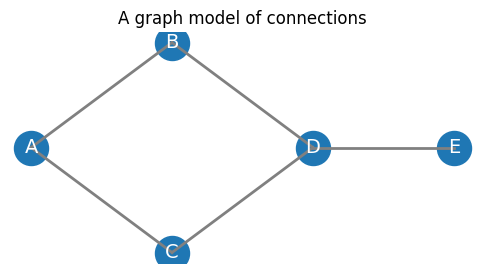

In [4]:
positions = {
    "A": (0, 1),
    "B": (1, 2),
    "C": (1, 0),
    "D": (2, 1),
    "E": (3, 1),
}

plt.figure(figsize=(6, 3))
for u, v in edges:
    x = [positions[u][0], positions[v][0]]
    y = [positions[u][1], positions[v][1]]
    plt.plot(x, y, color="gray", linewidth=2)
for node, (x, y) in positions.items():
    plt.scatter(x, y, s=600, color="tab:blue")
    plt.text(x, y, node, color="white", ha="center", va="center", fontsize=14)
plt.axis("off")
plt.title("A graph model of connections")
plt.show()

---


**Graph and graph modeling**

In [5]:
# Example interpretation: a simple contact network.
infection_state = {"A": "infected", "B": "susceptible", "C": "susceptible", "D": "susceptible", "E": "susceptible"}
risk_scores = {}
for node in nodes:
    infected_neighbors = sum(infection_state[n] == "infected" for n in adj_list[node])
    risk_scores[node] = infected_neighbors / max(1, len(adj_list[node]))

print("Risk score from infected neighbors:")
print(risk_scores)

Risk score from infected neighbors:
{'A': 0.0, 'B': 0.5, 'C': 0.5, 'D': 0.0, 'E': 0.0}
